# 02 — Modèle de niveau


In [1]:
import sys, os
sys.path.append("..")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src.data_loader import load, split_per_user, save_processed
DATA = "../data/raw/interactions_real_rich_processed.csv"
df = load(DATA)
train, test = split_per_user(df)

Text(0.5, 1.0, 'Niveau estimé des étudiants')

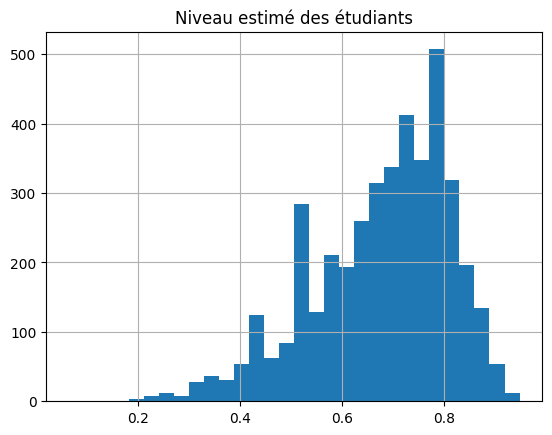

In [2]:
from src.student_model import StudentModel
sm = StudentModel().fit(train)
levels = pd.Series({u: sm.level(h) for u, h in sm.history.items()})
levels.hist(bins=30); plt.title('Niveau estimé des étudiants')

<Axes: title={'center': 'Difficulté par compétence (1 - taux moyen)'}>

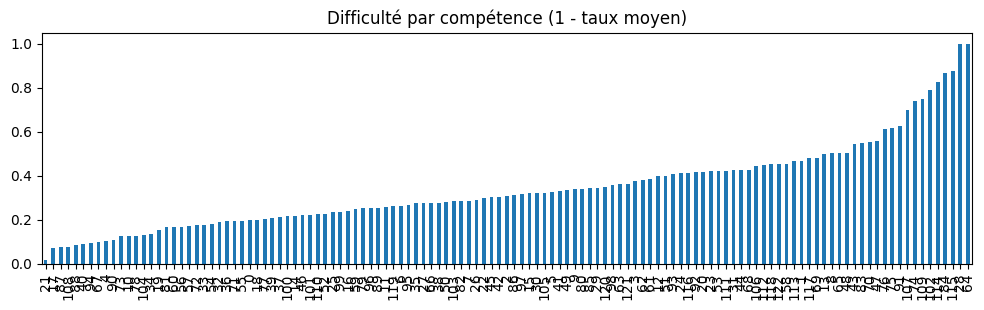

In [3]:
diffs = pd.Series({s: sm.difficulty(s) for s in sm.skills})
diffs.sort_values().plot(kind='bar', figsize=(12,3), title='Difficulté par compétence (1 - taux moyen)')

In [4]:
u = max(sm.history, key=lambda x: len(sm.history[x]))
sm.history[u].sort_values().head(10)  # compétences les moins maîtrisées de l'étudiant le plus actif

skill_id_new
84    0.250000
86    0.500000
91    0.500000
63    0.500000
25    0.571429
85    0.571429
24    0.600000
23    0.600000
54    0.600000
92    0.600000
Name: target_correct_rate, dtype: float64